# Jour 4 — Validation des clusters (Chapitre 4)

Objectifs :
1. **Indices internes** : silhouette, Davies-Bouldin, Dunn — toutes les méthodes, $k\in[2,10]$.
2. **Indices externes** par rapport à `y` (souscription) : ARI, NMI, homogénéité, complétude, V-mesure.
3. **Stabilité** : K-means relancé avec 20 graines + rééchantillonnage bootstrap, ARI entre exécutions.
4. **Sélection** de la meilleure solution en justifiant le compromis entre indices.

> Rappel : `y` n'a été utilisée par **aucun** algorithme. Elle intervient ici uniquement comme vérité terrain externe.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

from src.config import SEED, K_RANGE, DATA_PROC, FIGURES, RESULTS, MODELS
from src.preprocessing import load_processed
from src.metrics import dunn_index, external_indices, internal_indices, pairwise_ari

sns.set_theme(style="whitegrid", palette="tab10"); plt.rcParams["figure.dpi"] = 110
def save(fig, name): fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

d = load_processed()
idx = d["sample_idx"]; X_full = d["X_a"]; Xs = X_full[idx]
y_s = d["y"].iloc[idx].to_numpy(); y_full = d["y"].to_numpy()
D_euc = squareform(pdist(Xs)); D_gow = np.load(DATA_PROC / "D_gower_sample.npy")
L2 = joblib.load(RESULTS / "j2_labels_par_k.joblib"); L3 = joblib.load(RESULTS / "j3_labels.joblib")

## 1. Indices internes et externes pour toutes les méthodes et tous les $k$
Pour comparer des méthodes reposant sur des géométries différentes, **tous les indices internes sont calculés dans le même espace** : la représentation (a) de l'échantillon (n = 4 000). La silhouette sur Gower est ajoutée pour les méthodes « mixtes ».

In [2]:
families = {
    "K-means": L2["kmeans"], "K-medoids (Gower)": L2["kmedoids"], "K-prototypes": L2["kprototypes"],
    "GMM": L2["gmm"],
    "CAH Ward": {k: L3["hac"][("euclidienne", "ward", k)] for k in K_RANGE},
    "CAH average (Gower)": {k: L3["hac"][("gower", "average", k)] for k in K_RANGE},
}
rows = []
for name, labs in families.items():
    for k, lab in labs.items():
        lab = np.asarray(lab)
        ii = internal_indices(Xs, lab)
        ii["dunn"] = dunn_index(lab, D=D_euc)
        sil_g = silhouette_score(D_gow, lab, metric="precomputed")
        sizes = np.bincount(lab)
        rows.append({"méthode": name, "k": k, **ii, "silhouette_gower": sil_g,
                     "min_cluster_%": 100 * sizes.min() / len(lab), **external_indices(y_s, lab)})
for name, lab in [("DBSCAN (UMAP)", L3["dbscan_umap"]), ("DBSCAN (PCA)", L3["dbscan_pca"])]:
    ii = internal_indices(Xs, lab); ii["dunn"] = dunn_index(lab, D=D_euc)
    m = lab != -1
    sizes = np.bincount(lab[m])
    rows.append({"méthode": name, **ii, "silhouette_gower": silhouette_score(D_gow[np.ix_(m, m)], lab[m], metric="precomputed"),
                 "min_cluster_%": 100 * sizes.min() / len(lab), **external_indices(y_s, lab)})
res = pd.DataFrame(rows)
res.to_csv(RESULTS / "j4_indices_complets.csv", index=False)
res.round(3).head(12)

,méthode,k,noise_%,silhouette,davies_bouldin,dunn,silhouette_gower,min_cluster_%,ARI,NMI,homogeneite,completude,V_mesure
0,K-means,2,0.0,0.209,2.075,0.051,0.222,32.075,0.105,0.053,0.073,0.041,0.053
1,K-means,3,0.0,0.178,1.815,0.032,0.173,14.250,0.123,0.040,0.068,0.028,0.040
2,K-means,4,0.0,0.148,1.944,0.008,0.137,14.225,0.039,0.024,0.056,0.015,0.024
3,K-means,5,0.0,0.142,1.854,0.023,0.114,14.225,0.017,0.022,0.058,0.013,0.022
4,K-means,6,0.0,0.151,1.766,0.016,0.119,6.075,0.034,0.041,0.117,0.025,0.041
5,K-means,7,0.0,0.132,1.820,0.008,0.102,6.000,0.019,0.037,0.116,0.022,0.037
6,K-means,8,0.0,0.140,1.792,0.008,0.102,1.975,0.022,0.042,0.136,0.025,0.042
7,K-means,9,0.0,0.136,1.817,0.008,0.083,1.975,0.025,0.041,0.139,0.024,0.041
8,K-means,10,0.0,0.125,1.864,0.008,0.070,1.975,0.017,0.039,0.140,0.022,0.039
9,K-medoids (Gower),2,0.0,0.046,4.008,0.014,0.141,40.500,-0.013,0.007,0.011,0.006,0.007


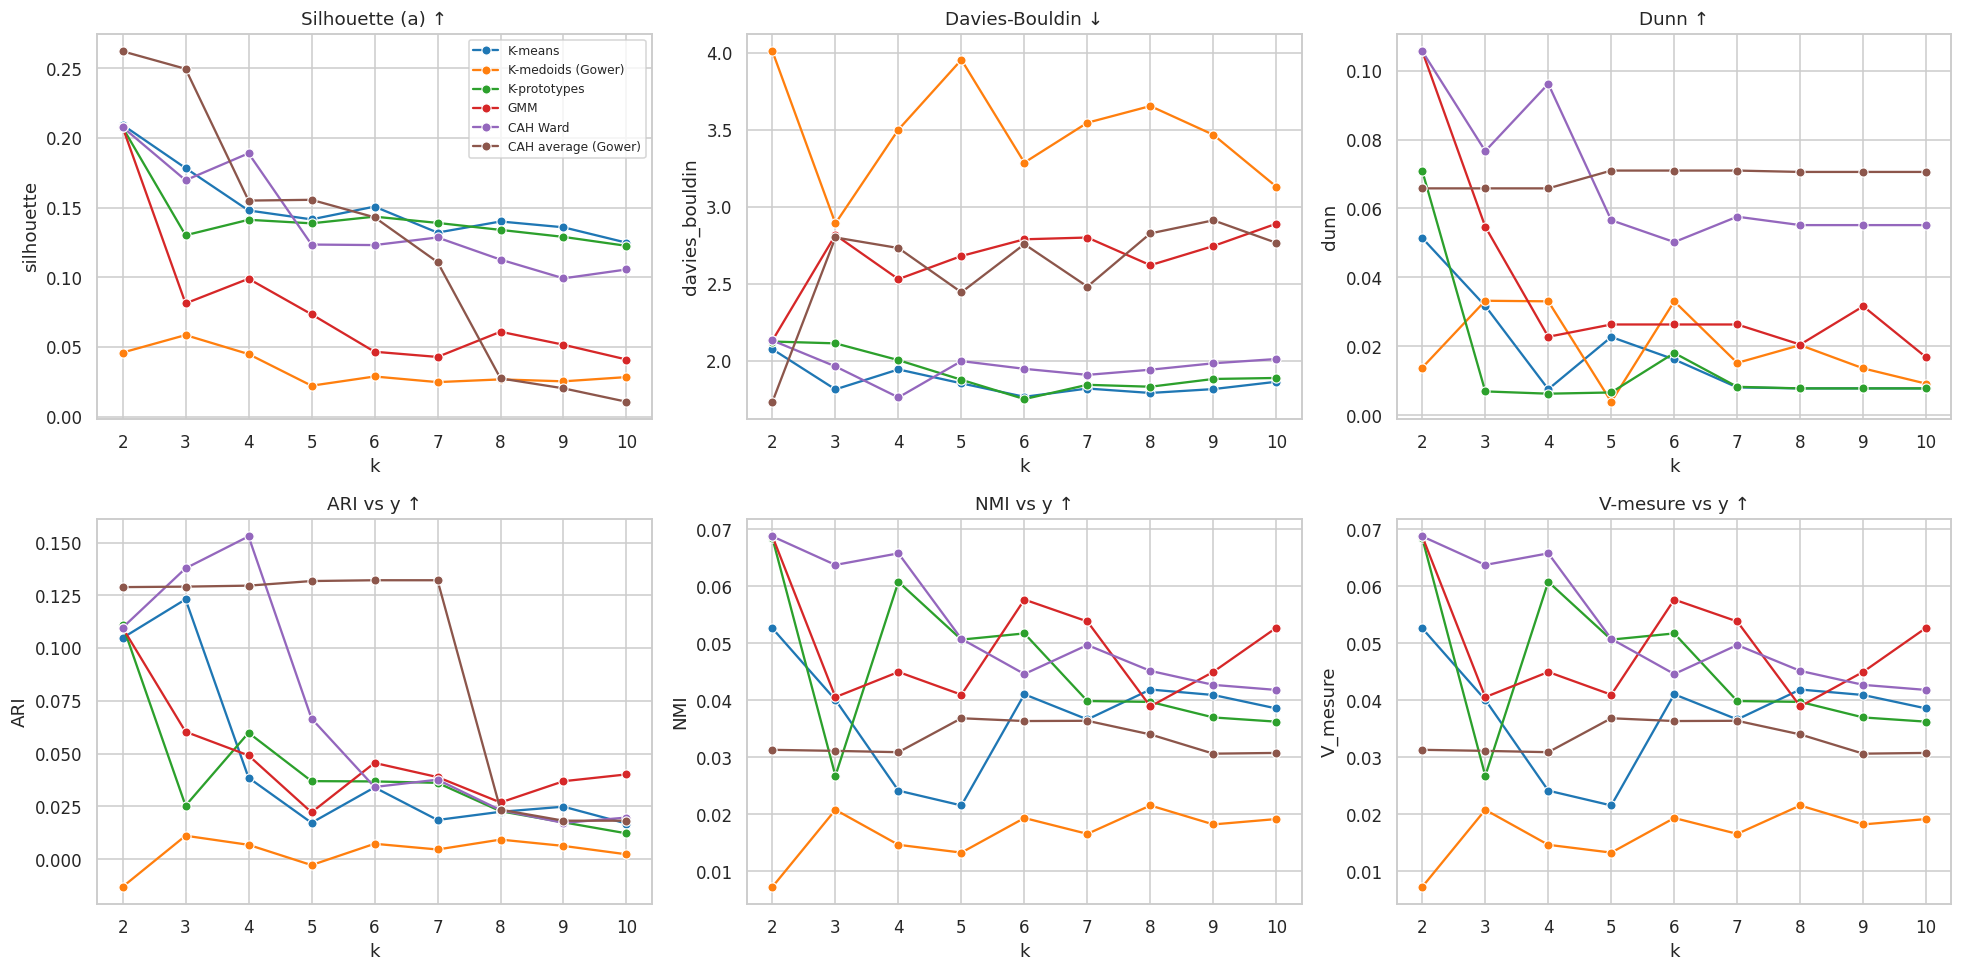

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
plot_df = res[~res["méthode"].str.startswith("DBSCAN")]
for ax, (col, t) in zip(axes.ravel(), [("silhouette", "Silhouette (a) ↑"), ("davies_bouldin", "Davies-Bouldin ↓"),
                                       ("dunn", "Dunn ↑"), ("ARI", "ARI vs y ↑"), ("NMI", "NMI vs y ↑"),
                                       ("V_mesure", "V-mesure vs y ↑")]):
    sns.lineplot(data=plot_df, x="k", y=col, hue="méthode", marker="o", ax=ax, legend=(col == "silhouette"))
    ax.set_title(t)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); save(fig, "j4_indices_par_k")

**Lecture des indices internes**
- La silhouette décroît globalement avec $k$ : la structure la plus marquée est grossière (2-3 groupes). Les méthodes euclidiennes (K-means, K-prototypes, Ward) dominent dans l'espace (a).
- L'indice de **Dunn** est très faible partout (< 0,1) : il dépend d'un seul couple de points (min / max) et est très sensible au moindre client atypique — attendu sur 4 000 points avec des groupes qui se touchent.
- **Davies-Bouldin** est le plus discriminant entre méthodes : K-means et K-prototypes restent les plus bas.

**Lecture des indices externes**
- ARI et NMI sont **faibles** (souvent < 0,1) : c'est **normal et même souhaitable**. Une segmentation de clientèle ne cherche pas à reproduire la décision de souscription (binaire, déséquilibrée) mais à décrire des profils ; un ARI élevé signifierait que l'on a simplement retrouvé `y`.
- L'**homogénéité** (chaque cluster contient-il une seule classe ?) est plus parlante que la complétude : on cherche des segments où le **taux de souscription varie fortement** (segments « chauds » et « froids »), ce que confirmera le profilage du Jour 5.

In [4]:
summary = (res.sort_values("silhouette", ascending=False)
           .groupby("méthode").head(1)[["méthode", "k", "silhouette", "davies_bouldin", "dunn", "silhouette_gower",
                                        "min_cluster_%", "ARI", "NMI", "homogeneite", "completude", "V_mesure"]])
summary.round(3)

,méthode,k,silhouette,davies_bouldin,dunn,silhouette_gower,min_cluster_%,ARI,NMI,homogeneite,completude,V_mesure
45,CAH average (Gower),2,0.262,1.735,0.066,0.243,14.025,0.129,0.031,0.034,0.029,0.031
0,K-means,2,0.209,2.075,0.051,0.222,32.075,0.105,0.053,0.073,0.041,0.053
27,GMM,2,0.208,2.132,0.106,0.229,34.600,0.110,0.069,0.097,0.053,0.069
36,CAH Ward,2,0.208,2.132,0.106,0.229,34.600,0.110,0.069,0.097,0.053,0.069
18,K-prototypes,2,0.208,2.125,0.071,0.228,34.300,0.111,0.068,0.097,0.053,0.068
55,DBSCAN (PCA),3,0.121,2.223,0.201,0.149,2.050,0.160,0.055,0.071,0.044,0.055
54,DBSCAN (UMAP),6,0.104,2.248,0.064,0.158,2.075,0.072,0.051,0.127,0.032,0.051
10,K-medoids (Gower),3,0.059,2.891,0.033,0.158,31.075,0.011,0.021,0.043,0.014,0.021


## 2. Étude de stabilité de K-means
### 2.1 Sensibilité à l'initialisation : 20 graines
On relance K-means **avec une seule initialisation** (`n_init=1`) pour 20 graines différentes et on mesure l'ARI entre toutes les paires d'exécutions (190 paires), pour chaque $k$.

In [5]:
seeds = list(range(20))
stab_rows = []
for k in K_RANGE:
    labs = [KMeans(k, n_init=1, random_state=s).fit_predict(X_full) for s in seeds]
    a = pairwise_ari(labs)
    stab_rows.append({"k": k, "ARI_graines_moy": a.mean(), "ARI_graines_min": a.min()})
seed_df = pd.DataFrame(stab_rows); seed_df.round(3)

,k,ARI_graines_moy,ARI_graines_min
0,2,0.932,0.353
1,3,0.605,0.098
2,4,0.666,0.426
3,5,0.860,0.558
4,6,0.730,0.380
5,7,0.649,0.426
6,8,0.692,0.343
7,9,0.672,0.439
8,10,0.662,0.437


### 2.2 Rééchantillonnage bootstrap
Pour chaque $k$ : un modèle de référence sur toutes les données ; 20 échantillons bootstrap (tirage avec remise, taille $n$) ; chaque modèle bootstrap affecte **toute la population** et on mesure l'ARI avec la référence.

,k,ARI_graines_moy,ARI_graines_min,ARI_bootstrap_moy,ARI_bootstrap_std
0,2,0.932,0.353,0.989,0.008
1,3,0.605,0.098,0.717,0.282
2,4,0.666,0.426,0.945,0.130
3,5,0.860,0.558,0.971,0.012
4,6,0.730,0.380,0.902,0.131
5,7,0.649,0.426,0.903,0.132
6,8,0.692,0.343,0.887,0.116
7,9,0.672,0.439,0.762,0.125
8,10,0.662,0.437,0.786,0.130


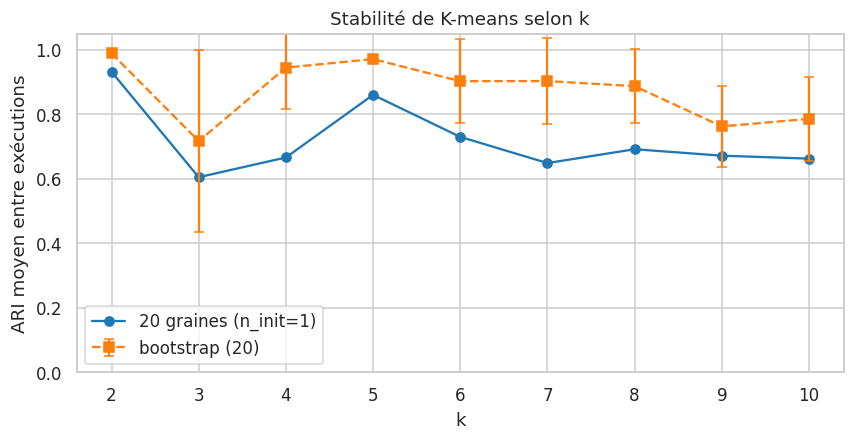

In [6]:
rng = np.random.default_rng(SEED)
boot_idx = [rng.integers(0, len(X_full), len(X_full)) for _ in range(20)]
for row in stab_rows:
    k = row["k"]
    ref = KMeans(k, n_init=10, random_state=SEED).fit(X_full).labels_
    aris = [adjusted_rand_score(ref, KMeans(k, n_init=3, random_state=SEED + b).fit(X_full[bi]).predict(X_full))
            for b, bi in enumerate(boot_idx)]
    row["ARI_bootstrap_moy"], row["ARI_bootstrap_std"] = np.mean(aris), np.std(aris)
stab = pd.DataFrame(stab_rows)
stab.to_csv(RESULTS / "j4_stabilite.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(stab["k"], stab["ARI_graines_moy"], "o-", label="20 graines (n_init=1)")
ax.errorbar(stab["k"], stab["ARI_bootstrap_moy"], yerr=stab["ARI_bootstrap_std"], fmt="s--", capsize=3, label="bootstrap (20)")
ax.set_xlabel("k"); ax.set_ylabel("ARI moyen entre exécutions"); ax.set_ylim(0, 1.05); ax.legend()
ax.set_title("Stabilité de K-means selon k"); save(fig, "j4_stabilite")
stab.round(3)

## 3. Sélection de la meilleure solution
Critères de décision (par ordre d'importance) :
1. **Actionnabilité** : 3 à 6 segments (le brief demande 3-4 recommandations), aucun segment < 5 % de la population ;
2. **Qualité interne** : silhouette ↑ et Davies-Bouldin ↓ dans l'espace commun ;
3. **Stabilité** : ARI bootstrap élevé ;
4. **Pouvoir discriminant métier** : homogénéité / V-mesure vis-à-vis de `y` (sans chercher à maximiser l'ARI) ;
5. **Déployabilité** : possibilité d'affecter un nouveau client (exclut CAH et DBSCAN).

On calcule un **score composite par rangs** (moyenne des rangs sur silhouette, Davies-Bouldin, V-mesure) parmi les solutions admissibles.

In [7]:
cand = res[(res["k"].between(3, 6)) & (res["min_cluster_%"] >= 5)].copy()
cand["rang_sil"] = cand["silhouette"].rank(ascending=False)
cand["rang_db"] = cand["davies_bouldin"].rank(ascending=True)
cand["rang_v"] = cand["V_mesure"].rank(ascending=False)
cand["score_rangs"] = cand[["rang_sil", "rang_db", "rang_v"]].mean(axis=1)
cand = cand.sort_values("score_rangs")
cand.to_csv(RESULTS / "j4_classement.csv", index=False)
cand[["méthode", "k", "silhouette", "davies_bouldin", "dunn", "V_mesure", "homogeneite", "ARI",
      "min_cluster_%", "score_rangs"]].head(10).round(3)

,méthode,k,silhouette,davies_bouldin,dunn,V_mesure,homogeneite,ARI,min_cluster_%,score_rangs
38,CAH Ward,4,0.189,1.763,0.096,0.066,0.128,0.153,8.125,1.000
37,CAH Ward,3,0.170,1.964,0.077,0.064,0.112,0.138,15.075,4.333
4,K-means,6,0.151,1.766,0.016,0.041,0.117,0.034,6.075,5.000
1,K-means,3,0.178,1.815,0.032,0.040,0.068,0.123,14.250,5.667
21,K-prototypes,5,0.139,1.877,0.007,0.051,0.133,0.037,7.950,6.333
20,K-prototypes,4,0.141,2.005,0.006,0.061,0.139,0.060,8.275,6.667
39,CAH Ward,5,0.124,1.998,0.057,0.051,0.128,0.067,8.125,8.000
2,K-means,4,0.148,1.944,0.008,0.024,0.056,0.039,14.225,8.333
3,K-means,5,0.142,1.854,0.023,0.022,0.058,0.017,14.225,8.333
40,CAH Ward,6,0.123,1.948,0.050,0.045,0.129,0.034,8.125,8.667


**Résultat du classement** : la **CAH Ward à k = 4** arrive première sur les trois critères à la fois (meilleure silhouette admissible, plus faible Davies-Bouldin, meilleure V-mesure) avec un plus petit segment de 8 %. Mais la CAH ne sait pas **affecter un nouveau client** et ne passe pas à l'échelle des 41 000 clients ($O(n^2)$).

➡️ Solution retenue : **classification mixte** (approche classique en analyse des données) — la CAH Ward fixe le nombre de classes et fournit des centres initiaux, puis une **consolidation par K-means** sur la population complète (initialisée avec les 4 barycentres Ward). On obtient un modèle déployable (centroïdes) qui hérite de la qualité de Ward.

In [8]:
k_best = 4
ward4 = families["CAH Ward"][k_best]
centres_ward = np.vstack([Xs[ward4 == c].mean(axis=0) for c in range(k_best)])
final = KMeans(n_clusters=k_best, init=centres_ward, n_init=1, random_state=SEED).fit(X_full)
labels_full = final.labels_
lab_s = labels_full[idx]
print("Accord Ward ↔ consolidation (ARI sur l'échantillon) :", round(adjusted_rand_score(ward4, lab_s), 3))
ii = internal_indices(Xs, lab_s); ii["dunn"] = dunn_index(lab_s, D=D_euc)
cons_row = {"méthode": "Ward + K-means (retenue)", "k": k_best, **ii,
            "silhouette_gower": silhouette_score(D_gow, lab_s, metric="precomputed"),
            "min_cluster_%": 100 * np.bincount(labels_full).min() / len(labels_full), **external_indices(y_s, lab_s)}
pd.Series(cons_row).to_frame("valeur")

Accord Ward ↔ consolidation (ARI sur l'échantillon) : 0.981


,valeur
méthode,Ward + K-means (retenue)
k,4
noise_%,0.0
silhouette,0.192232
davies_bouldin,1.69008
dunn,0.053363
silhouette_gower,0.174455
min_cluster_%,6.171071
ARI,0.151228
NMI,0.061704


In [9]:
# Stabilité de la solution mixte : bootstrap de toute la chaîne (CAH Ward sur l'échantillon → K-means)
from scipy.cluster.hierarchy import fcluster, linkage
rng = np.random.default_rng(SEED); aris = []
for b in range(20):
    bi = rng.choice(len(Xs), len(Xs)); Xb = Xs[bi]
    wb = fcluster(linkage(Xb, "ward"), k_best, "maxclust") - 1
    Cb = np.vstack([Xb[wb == c].mean(axis=0) for c in range(k_best)])
    aris.append(adjusted_rand_score(labels_full, KMeans(k_best, init=Cb, n_init=1).fit(X_full).labels_))
aris = np.array(aris)
print(f"ARI bootstrap de la chaîne complète : {aris.mean():.3f} ± {aris.std():.3f} | médiane {np.median(aris):.3f}")
print(f"Part des réplications avec ARI > 0,9 : {(aris > 0.9).mean():.0%}")
cons_row["ARI_bootstrap"] = aris.mean()

ARI bootstrap de la chaîne complète : 0.716 ± 0.233 | médiane 0.518
Part des réplications avec ARI > 0,9 : 40%


In [10]:
# Stabilité de la partition finale vis-à-vis de l'échantillonnage (centres Ward fixés, 20 bootstraps de la population)
aris_fin = []
for b in range(20):
    bi = rng.integers(0, len(X_full), len(X_full))
    aris_fin.append(adjusted_rand_score(labels_full, KMeans(k_best, init=final.cluster_centers_, n_init=1).fit(X_full[bi]).predict(X_full)))
aris_fin = np.array(aris_fin)
km4 = KMeans(k_best, n_init=10, random_state=SEED).fit(X_full)
print(f"ARI bootstrap (consolidation, init fixée) : {aris_fin.mean():.4f} ± {aris_fin.std():.4f}")
print(f"Inertie : consolidation Ward→K-means = {final.inertia_:,.0f} | K-means k=4 standard = {km4.inertia_:,.0f}")
print(f"ARI entre les deux solutions k=4 : {adjusted_rand_score(labels_full, km4.labels_):.3f}")

ARI bootstrap (consolidation, init fixée) : 0.9994 ± 0.0002
Inertie : consolidation Ward→K-means = 243,332 | K-means k=4 standard = 234,094
ARI entre les deux solutions k=4 : 0.518


**Lecture de la stabilité**
- **K-means seul** : stable en bootstrap pour k = 2, 4, 5 (ARI ≥ 0,94), plus fragile à k = 3 et k ≥ 9 ; la sensibilité à l'initialisation (20 graines, `n_init=1`) est réelle (ARI moyen 0,6-0,9) → d'où `n_init ≥ 10` en pratique.
- **Solution retenue** : une fois les centres Ward fixés, la partition est **extrêmement stable** au rééchantillonnage (ARI ≈ 0,999). L'instabilité vient de la **chaîne complète** (ARI 0,72 ± 0,23) : sur certains bootstraps, la CAH coupe différemment les petits groupes (seniors / déjà contactés). C'est une limite à documenter ; elle plaide pour **figer** les centres de référence et les ré-estimer périodiquement.
- La consolidation a une inertie un peu plus élevée que K-means standard (optimum local différent) mais une **meilleure silhouette (0,192 vs 0,148) et un meilleur Davies-Bouldin (1,69 vs 1,94)** : elle sépare mieux les groupes au lieu de seulement réduire la variance intra.
- Indices externes : ARI = 0,157, homogénéité = 0,125 — les meilleurs parmi les solutions admissibles, et surtout des taux de souscription très contrastés (4,9 % → 42,5 %), analysés au Jour 5.

In [11]:
# Tableau de synthèse final (livrable J4) : meilleure solution admissible de chaque famille + DBSCAN + solution retenue
synth = pd.concat([cand.groupby("méthode").head(1), res[res["méthode"].str.startswith("DBSCAN")],
                   pd.DataFrame([cons_row])])
synth = synth[["méthode", "k", "silhouette", "davies_bouldin", "dunn", "silhouette_gower", "ARI", "NMI",
               "homogeneite", "completude", "V_mesure", "min_cluster_%"]].reset_index(drop=True)
synth.to_csv(RESULTS / "j4_synthese.csv", index=False)
synth.round(3)

,méthode,k,silhouette,davies_bouldin,dunn,silhouette_gower,ARI,NMI,homogeneite,completude,V_mesure,min_cluster_%
0,CAH Ward,4,0.189,1.763,0.096,0.168,0.153,0.066,0.128,0.044,0.066,8.125
1,K-means,6,0.151,1.766,0.016,0.119,0.034,0.041,0.117,0.025,0.041,6.075
2,K-prototypes,5,0.139,1.877,0.007,0.102,0.037,0.051,0.133,0.031,0.051,7.950
3,GMM,4,0.099,2.530,0.023,0.169,0.049,0.045,0.106,0.029,0.045,16.900
4,K-medoids (Gower),3,0.059,2.891,0.033,0.158,0.011,0.021,0.043,0.014,0.021,31.075
5,DBSCAN (UMAP),6,0.104,2.248,0.064,0.158,0.072,0.051,0.127,0.032,0.051,2.075
6,DBSCAN (PCA),3,0.121,2.223,0.201,0.149,0.160,0.055,0.071,0.044,0.055,2.050
7,Ward + K-means (retenue),4,0.192,1.690,0.053,0.174,0.151,0.062,0.118,0.042,0.062,6.171


## 4. Modèle final sur la population complète

In [12]:
joblib.dump(final, MODELS / "kmeans_final.joblib")
np.save(DATA_PROC / "labels_final.npy", labels_full)
pd.DataFrame({"ARI_chaine": aris, "ARI_consolidation": aris_fin}).to_csv(RESULTS / "j4_stabilite_solution_finale.csv", index=False)
print("Tailles des segments :", np.bincount(labels_full))
print("Indices externes (population complète) :", {k: round(v, 4) for k, v in external_indices(y_full, labels_full).items()})
print("Taux de souscription par segment :", pd.Series(y_full).groupby(labels_full).mean().round(3).to_dict())

Tailles des segments : [26939  7015  2541  4681]
Indices externes (population complète) : {'ARI': 0.1569, 'NMI': 0.0654, 'homogeneite': 0.1254, 'completude': 0.0442, 'V_mesure': 0.0654}
Taux de souscription par segment : {0: 0.049, 1: 0.173, 2: 0.425, 3: 0.22}
